# 🛒 Spinneys Product Intelligence — Exploratory Data Analysis
**Notebook:** `01_spinneys_eda.ipynb`  
**Project:** Spinneys Conversational Shopping Assistant  
**Database:** `spinneys_database` (MySQL 8.0)  
**Author:** AI Engineering Team  

---

## Table of Contents
1. [Environment Setup & DB Connection](#1-environment-setup)
2. [Database Scale — 30-Table Inventory](#2-database-scale)
3. [Product Name Analysis & Duplicates](#3-product-names)
4. [Price Distribution, Boxplot & Anomalies](#4-pricing)
5. [Inventory Analysis — Multi-Source Conflict Resolution](#5-inventory)
6. [Brand Coverage — Before & After Imputation + Normalization](#6-brands)
7. [Category Analysis — Unique Departments & Test Exclusion](#7-categories)
8. [Results Export & Documentation Summary](#8-export)


---
## 1. Environment Setup & DB Connection

We load credentials from `.env`, establish a MySQL connection, and confirm
all required libraries are available.


In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# Project root
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

import pymysql
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from dotenv import load_dotenv
from IPython.display import display, Markdown

load_dotenv(ROOT / '.env')

# ── Corporate Style ──────────────────────────────────────────────────────────
NAVY   = '#1B365D'
TEAL   = '#008080'
SLATE  = '#4A6FA5'
MINT   = '#52B788'
AMBER  = '#F4A261'
RED    = '#C62828'
LGRAY  = '#F5F5F5'
PALETTE = [TEAL, NAVY, SLATE, MINT, AMBER, RED, '#7B1FA2', '#00695C', '#E65100', '#0277BD']

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   LGRAY,
    'axes.edgecolor':   '#BDBDBD',
    'axes.labelcolor':  NAVY,
    'axes.titlecolor':  NAVY,
    'axes.titlesize':   13,
    'axes.labelsize':   11,
    'xtick.color':      NAVY,
    'ytick.color':      NAVY,
    'font.family':      'DejaVu Sans',
    'figure.dpi':       120,
    'grid.color':       '#E0E0E0',
    'grid.linewidth':   0.8,
})

# ── DB Connection helper ─────────────────────────────────────────────────────
DB_CFG = dict(
    host=os.getenv('MYSQL_HOST', 'localhost'),
    port=int(os.getenv('MYSQL_PORT', 3306)),
    user=os.getenv('MYSQL_USER', 'root'),
    password=os.getenv('MYSQL_PASSWORD', '1234'),
    database=os.getenv('MYSQL_DATABASE', 'spinneys_database'),
    charset='utf8mb4',
    connect_timeout=30,
)

def qry(sql, params=None):
    """Run SQL, return DataFrame."""
    with pymysql.connect(**DB_CFG) as c:
        return pd.read_sql(sql, c, params=params)

# ── Connection test ──────────────────────────────────────────────────────────
test = qry('SELECT VERSION() AS ver, DATABASE() AS db')
display(test)
print('✅  MySQL connection OK')


,ver,db
0,8.0.46,spinneys_database


✅  MySQL connection OK


---
## 2. Database Scale — 30-Table Inventory

We query `information_schema` to list all tables, their estimated row counts,
and data sizes. This gives us a clear picture of catalogue scope.


In [2]:
tables_df = qry("""
    SELECT
        TABLE_NAME,
        TABLE_ROWS       AS est_rows,
        ROUND(DATA_LENGTH / 1024 / 1024, 2)   AS data_mb,
        ROUND(INDEX_LENGTH / 1024 / 1024, 2)  AS index_mb,
        CREATE_TIME
    FROM information_schema.TABLES
    WHERE TABLE_SCHEMA = 'spinneys_database'
    ORDER BY est_rows DESC
""")

print(f'📊  Total tables in spinneys_database: {len(tables_df)}')
display(tables_df.style
    .background_gradient(subset=['est_rows'], cmap='Blues')
    .format({'est_rows': '{:,.0f}', 'data_mb': '{:.2f} MB', 'index_mb': '{:.2f} MB'})
    .set_caption('Table Inventory — spinneys_database')
)


📊  Total tables in spinneys_database: 30


,TABLE_NAME,est_rows,data_mb,index_mb,CREATE_TIME
0,catalog_productstock,"600,975",36.56 MB,44.67 MB,2026-10-06 12:47:48
1,catalog_productprice,"273,244",18.55 MB,35.61 MB,2026-10-06 12:47:41
2,catalog_productdescription,"133,036",8.52 MB,4.52 MB,2026-10-06 12:47:38
3,catalog_productname,"50,084",6.52 MB,8.55 MB,2026-10-06 12:47:40
4,catalog_product_categories,"49,910",3.52 MB,4.03 MB,2026-10-06 12:47:23
5,catalog_productattributes,"33,796",286.83 MB,7.03 MB,2026-10-06 12:47:24
6,catalog_product,"26,003",5.52 MB,1.52 MB,2026-10-06 12:47:22
7,recommendations_productembedding,"25,141",328.88 MB,5.03 MB,2026-10-06 12:48:03
8,catalog_categoryname,544,0.06 MB,0.03 MB,2026-10-06 12:47:22
9,catalog_category,272,0.02 MB,0.05 MB,2026-10-06 12:47:22


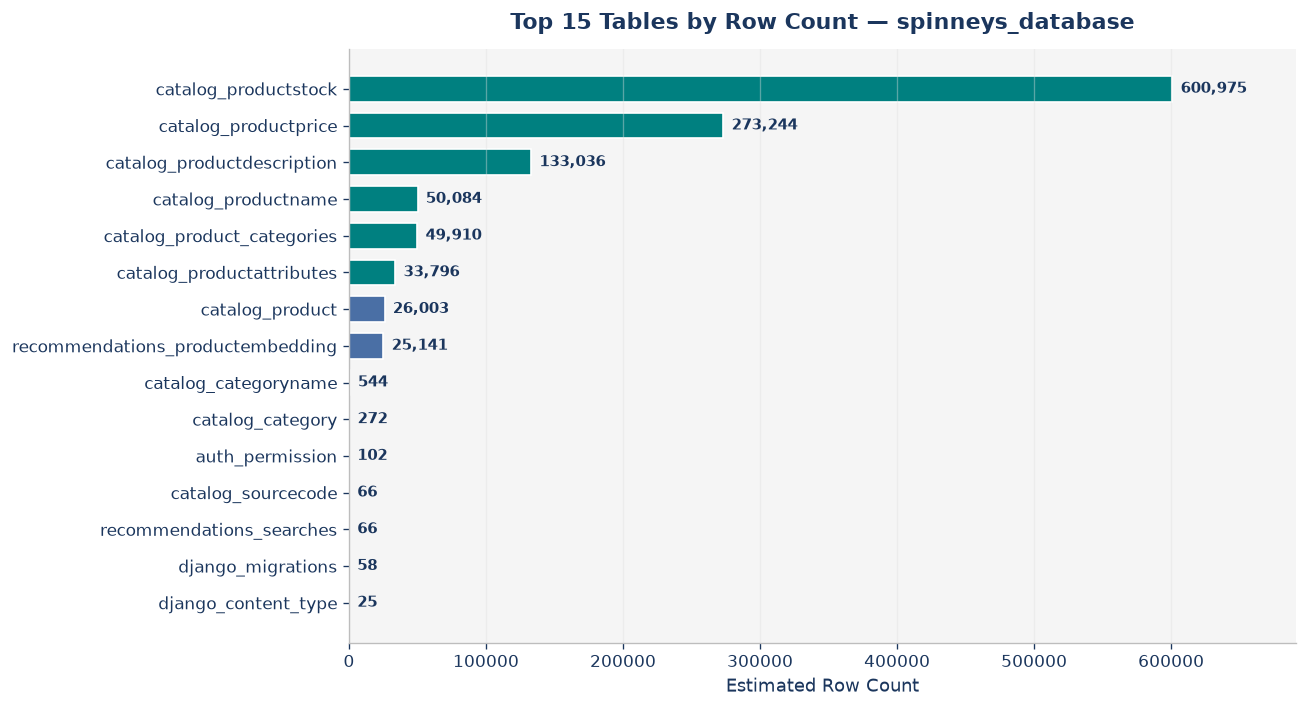

In [3]:
# ── Visual: Tables by estimated row count ────────────────────────────────────
top_t = tables_df.nlargest(15, 'est_rows').sort_values('est_rows')

fig, ax = plt.subplots(figsize=(11, 6))
colors = [TEAL if i >= len(top_t)-6 else SLATE for i in range(len(top_t))]
bars = ax.barh(top_t['TABLE_NAME'], top_t['est_rows'], color=colors, edgecolor='white', height=0.7)
for bar, val in zip(bars, top_t['est_rows']):
    ax.text(bar.get_width() + top_t['est_rows'].max()*0.01,
            bar.get_y() + bar.get_height()/2,
            f'{int(val):,}', va='center', fontsize=9, color=NAVY, fontweight='bold')
ax.set_xlabel('Estimated Row Count')
ax.set_title('Top 15 Tables by Row Count — spinneys_database', fontweight='bold', pad=12)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='x', alpha=0.4)
ax.set_xlim(0, top_t['est_rows'].max() * 1.15)
plt.tight_layout()
plt.savefig('../reports/assets/eda_tables.png', dpi=130, bbox_inches='tight')
plt.show()


---
## 3. Product Name Analysis & Duplicate Discovery

We analyse `catalog_productname` to:
- Count products per language
- Identify exact-name duplicates (same name, different product_id)
- Detect products with missing English names


In [4]:
# ── Language coverage ────────────────────────────────────────────────────────
lang_df = qry("""
    SELECT language,
           COUNT(DISTINCT product_id) AS products,
           COUNT(*) AS total_rows
    FROM catalog_productname
    GROUP BY language
    ORDER BY products DESC
""")
display(lang_df)

total_products = qry('SELECT COUNT(*) AS n FROM catalog_product').iloc[0,0]
en_products    = lang_df[lang_df['language']=='English']['products'].values
en_count       = int(en_products[0]) if len(en_products) else 0
missing_en     = total_products - en_count

display(Markdown(f"""
| Metric | Value |
|--------|-------|
| Total products in catalog | **{total_products:,}** |
| With English name | **{en_count:,}** ({en_count/total_products*100:.1f}%) |
| Missing English name | **{missing_en:,}** — excluded from index |
"""))


,language,products,total_rows
0,Arabic,25881,25881
1,English,25881,25881



| Metric | Value |
|--------|-------|
| Total products in catalog | **25,881** |
| With English name | **25,881** (100.0%) |
| Missing English name | **0** — excluded from index |


In [5]:
# ── Exact-name duplicates ────────────────────────────────────────────────────
dup_df = qry("""
    SELECT name, COUNT(DISTINCT product_id) AS product_count
    FROM catalog_productname
    WHERE language = 'English'
    GROUP BY name
    HAVING product_count > 1
    ORDER BY product_count DESC
    LIMIT 20
""")

print(f'🔁  Duplicate product names (English): {len(dup_df)} unique names appear >1 time')
display(dup_df.style
    .background_gradient(subset=['product_count'], cmap='Reds')
    .set_caption('Top 20 Duplicate Product Names')
)


🔁  Duplicate product names (English): 20 unique names appear >1 time


,name,product_count
0,Red Cabbages - 1 Piece,7
1,White Cabbages - 1 Piece,7
2,Iceberg Lettuces - 1 Piece,6
3,Cucumbers,5
4,Cucumbers - 1 Kilo,5
5,Green Beans,5
6,Modern Turkish Coffe Pot With Bakelit,5
7,"Spinneys Cups Cartoon Printed, 1 Piece - (Assorted)",5
8,Sweet Corns - 3 Pieces,5
9,Tomatoes - 1 Kilo,5


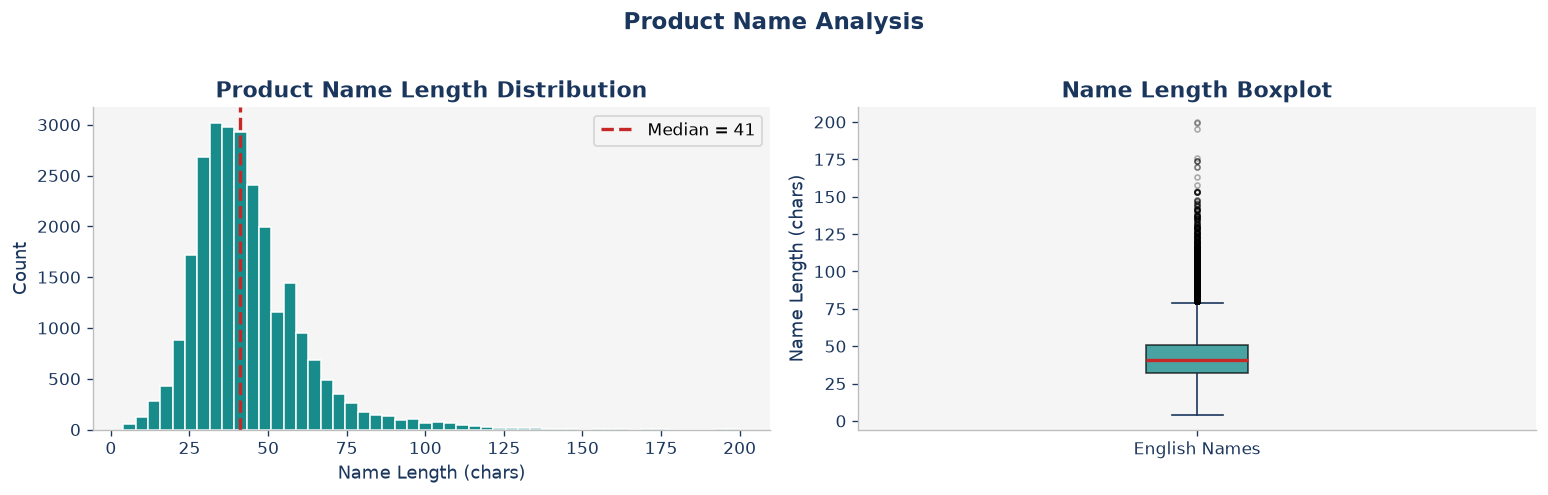

  Mean length: 43.4 chars
  Median:      41 chars
  Max:         208 chars
  Very short (<5 chars): 5 products


In [6]:
# ── Name length distribution ─────────────────────────────────────────────────
name_len_df = qry("""
    SELECT CHAR_LENGTH(name) AS name_length
    FROM catalog_productname
    WHERE language = 'English' AND name IS NOT NULL
""")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
ax = axes[0]
ax.hist(name_len_df['name_length'].clip(upper=200), bins=50, color=TEAL, edgecolor='white', alpha=0.9)
ax.axvline(name_len_df['name_length'].median(), color=RED, lw=2, linestyle='--',
           label=f'Median = {name_len_df["name_length"].median():.0f}')
ax.set_xlabel('Name Length (chars)')
ax.set_ylabel('Count')
ax.set_title('Product Name Length Distribution', fontweight='bold')
ax.legend()
ax.spines[['top','right']].set_visible(False)

# Boxplot
ax2 = axes[1]
ax2.boxplot(name_len_df['name_length'].clip(upper=200), patch_artist=True,
            boxprops=dict(facecolor=TEAL, alpha=0.7),
            medianprops=dict(color=RED, linewidth=2),
            whiskerprops=dict(color=NAVY),
            capprops=dict(color=NAVY),
            flierprops=dict(marker='.', color=AMBER, alpha=0.3))
ax2.set_ylabel('Name Length (chars)')
ax2.set_title('Name Length Boxplot', fontweight='bold')
ax2.set_xticklabels(['English Names'])
ax2.spines[['top','right']].set_visible(False)

plt.suptitle('Product Name Analysis', fontsize=14, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
plt.savefig('../reports/assets/eda_name_length.png', dpi=130, bbox_inches='tight')
plt.show()

print(f'  Mean length: {name_len_df["name_length"].mean():.1f} chars')
print(f'  Median:      {name_len_df["name_length"].median():.0f} chars')
print(f'  Max:         {name_len_df["name_length"].max()} chars')
print(f'  Very short (<5 chars): {(name_len_df["name_length"] < 5).sum()} products')


---
## 4. Price Distribution, Boxplot & Anomaly Detection

We analyse `catalog_product.default_price` and `default_special_price` to:
- Identify zero-price and NULL anomalies
- Visualize price distribution across EGP buckets
- Detect unrealistic discounts (≥ 80% off)
- Compare default vs effective (promotional) price


In [7]:
# ── Load price data ──────────────────────────────────────────────────────────
price_df = qry("""
    SELECT id AS product_id,
           default_price,
           default_special_price,
           CASE
               WHEN default_special_price IS NOT NULL
                    AND default_special_price > 0
                    AND default_special_price < default_price
               THEN default_special_price
               ELSE default_price
           END AS effective_price
    FROM catalog_product
""")

# ── Anomaly summary ──────────────────────────────────────────────────────────
zero_price   = (price_df['default_price'] == 0).sum()
null_price   = price_df['default_price'].isna().sum()
valid_price  = (price_df['default_price'] > 0).sum()

disc_df = price_df[
    price_df['default_special_price'].notna() &
    (price_df['default_special_price'] > 0) &
    (price_df['default_special_price'] < price_df['default_price'])
].copy()
disc_df['disc_pct'] = (1 - disc_df['default_special_price'] / disc_df['default_price']) * 100
extreme_disc = (disc_df['disc_pct'] >= 80).sum()

display(Markdown(f"""
### Price Anomaly Summary
| Metric | Count | Note |
|--------|-------|------|
| Zero price (`default_price = 0`) | **{zero_price:,}** | ❌ Excluded from index |
| NULL price | **{null_price:,}** | ❌ Excluded |
| Valid price (> 0) | **{valid_price:,}** | ✅ Indexed |
| Products with valid discount | **{len(disc_df):,}** | |
| Extreme discounts (≥80%) | **{extreme_disc:,}** | ⚠️ Possible data error |
"""))



### Price Anomaly Summary
| Metric | Count | Note |
|--------|-------|------|
| Zero price (`default_price = 0`) | **78** | ❌ Excluded from index |
| NULL price | **0** | ❌ Excluded |
| Valid price (> 0) | **25,803** | ✅ Indexed |
| Products with valid discount | **782** | |
| Extreme discounts (≥80%) | **43** | ⚠️ Possible data error |


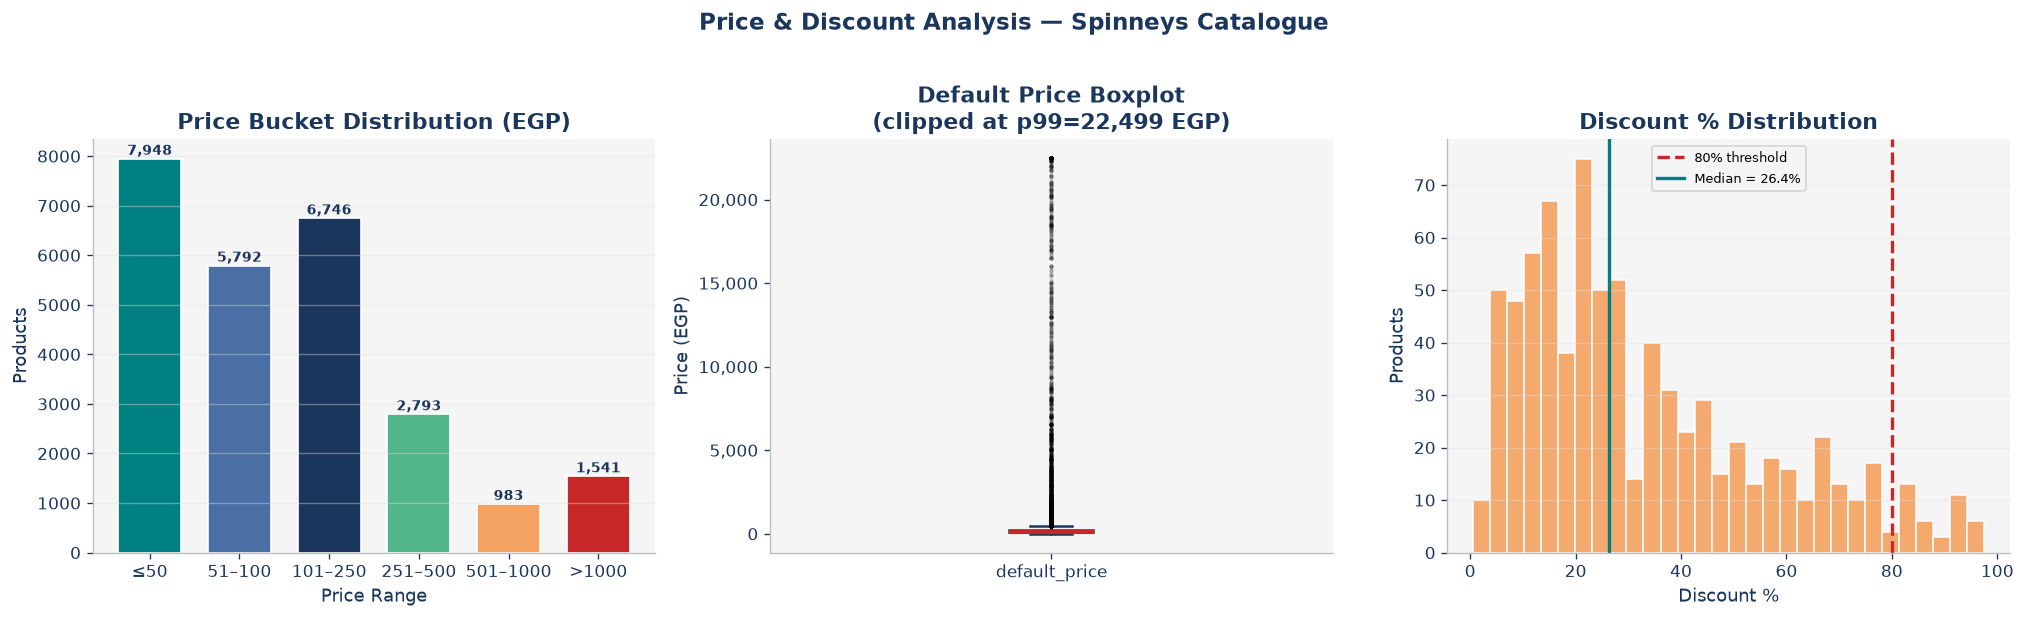

  Mean price:   766.01 EGP
  Median price: 91.95 EGP
  Max price:    169,599.00 EGP
  Mean discount: 33.0%
  Extreme discounts (≥80%): 43


In [8]:
# ── Price Distribution Charts ────────────────────────────────────────────────
valid_df = price_df[price_df['default_price'] > 0].copy()

buckets = [0, 50, 100, 250, 500, 1000, float('inf')]
labels  = ['≤50', '51–100', '101–250', '251–500', '501–1000', '>1000']
valid_df['bucket'] = pd.cut(valid_df['effective_price'], bins=buckets, labels=labels, right=True)
bucket_counts = valid_df['bucket'].value_counts().reindex(labels).fillna(0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Bar chart — buckets
ax = axes[0]
bcolors = [TEAL, SLATE, NAVY, MINT, AMBER, RED]
bars = ax.bar(labels, bucket_counts.values, color=bcolors, edgecolor='white', width=0.7)
for bar, val in zip(bars, bucket_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + bucket_counts.max()*0.01,
            f'{val:,}', ha='center', fontsize=8.5, color=NAVY, fontweight='bold')
ax.set_title('Price Bucket Distribution (EGP)', fontweight='bold')
ax.set_xlabel('Price Range')
ax.set_ylabel('Products')
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=0.4)

# Boxplot — default_price (clipped)
ax2 = axes[1]
clip_99 = valid_df['default_price'].quantile(0.99)
ax2.boxplot(valid_df['default_price'].clip(upper=clip_99),
            patch_artist=True, notch=False,
            boxprops=dict(facecolor=TEAL, alpha=0.7),
            medianprops=dict(color=RED, linewidth=2.5),
            whiskerprops=dict(color=NAVY, linewidth=1.5),
            capprops=dict(color=NAVY, linewidth=1.5),
            flierprops=dict(marker='.', color=AMBER, alpha=0.2, markersize=3))
ax2.set_title(f'Default Price Boxplot\n(clipped at p99={clip_99:,.0f} EGP)', fontweight='bold')
ax2.set_xticklabels(['default_price'])
ax2.set_ylabel('Price (EGP)')
ax2.spines[['top','right']].set_visible(False)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Discount distribution
ax3 = axes[2]
if len(disc_df) > 0:
    ax3.hist(disc_df['disc_pct'].clip(upper=100), bins=30, color=AMBER, edgecolor='white', alpha=0.9)
    ax3.axvline(80, color=RED, lw=2, linestyle='--', label='80% threshold')
    ax3.axvline(disc_df['disc_pct'].median(), color=TEAL, lw=2, linestyle='-',
                label=f'Median = {disc_df["disc_pct"].median():.1f}%')
    ax3.set_title('Discount % Distribution', fontweight='bold')
    ax3.set_xlabel('Discount %')
    ax3.set_ylabel('Products')
    ax3.legend(fontsize=8)
    ax3.spines[['top','right']].set_visible(False)
    ax3.grid(axis='y', alpha=0.4)

plt.suptitle('Price & Discount Analysis — Spinneys Catalogue', fontsize=14, fontweight='bold',
             color=NAVY, y=1.02)
plt.tight_layout()
plt.savefig('../reports/assets/eda_price.png', dpi=130, bbox_inches='tight')
plt.show()

print(f'  Mean price:   {valid_df["default_price"].mean():,.2f} EGP')
print(f'  Median price: {valid_df["default_price"].median():,.2f} EGP')
print(f'  Max price:    {valid_df["default_price"].max():,.2f} EGP')
if len(disc_df):
    print(f'  Mean discount: {disc_df["disc_pct"].mean():.1f}%')
    print(f'  Extreme discounts (≥80%): {extreme_disc}')


In [9]:
# ── Top 10 most expensive products ──────────────────────────────────────────
top_price = qry("""
    SELECT p.id, p.sku, pn.name AS product_name,
           p.default_price, p.default_special_price
    FROM catalog_product p
    JOIN catalog_productname pn ON pn.product_id = p.id AND pn.language = 'English'
    WHERE p.default_price > 0
    ORDER BY p.default_price DESC
    LIMIT 10
""")
display(top_price.style
    .background_gradient(subset=['default_price'], cmap='YlOrRd')
    .format({'default_price': '{:,.2f}', 'default_special_price': '{:,.2f}'})
    .set_caption('Top 10 Most Expensive Products')
)


,id,sku,product_name,default_price,default_special_price
0,8963,405572,Sharp Home Freezer 6 Drawers No Frost Black Fj-Ec2 - 250L,"169,599.00","169,599.00"
1,14499,361332,"Sharp Digital Refrigerator With Water Dispenser, No Frost, 565 Liters, 2 Doors, Silver - Sj-Bg725D-Ss","122,325.00","122,325.00"
2,8813,349691,"Carrier Prestige Pro Floor Ceiling Air Conditioner, 5 Hp, Cool-Heat, 53Qflt36N-708","92,305.00","92,305.00"
3,22205,329579,"Lg Refrigerator With Water Dispenser, 631L, Silver - Gr-F822Hlhu","73,990.00","73,990.00"
4,8699,329580,"LG Refrigerator Led Display, 631L - Gr-H822Hlhu","72,290.00","72,290.00"
5,25054,417014,Lg Wm With Dryer 11Kg-F0L2Crv2Tc.Asspeec - 20Kg,"63,990.00","63,990.00"
6,15196,404654,Lg Uhd Smart Screen Tv 4K With Built In Reciever - 86In,"59,499.00","59,499.00"
7,22848,435736,"Sharp Inverter Refrigerator with Bottom Freezer, 558L, Silver - Sj-Gv73J-Sl","57,200.00","57,200.00"
8,20784,431601,"Sharp Inverter Digital Fridge With Bottom Frezzer , Black , 558L - Sj - Gv73J - Bk","57,099.00","57,099.00"
9,26584,396032,"LG No Frost Refrigerator, 410 Liters, Dark Silver - GN H722HLHL","56,990.00","56,990.00"


---
## 5. Inventory Analysis — Multi-Source Conflict Resolution

The `catalog_productstock` table has a composite key on `(sku, source_code)`,
meaning one SKU can appear in multiple warehouse locations with different quantities.

**Conflict resolution policy:** `SUM(quantity)` across all sources.
- If SUM > 0 → **In Stock** (even if some sources show 0)
- If SUM = 0 → **Out of Stock**
- If no record in stock table → **Unknown** → treated as Out of Stock (conservative)


In [10]:
# ── Stock source analysis ────────────────────────────────────────────────────
sources_df = qry("""
    SELECT source_code,
           COUNT(DISTINCT sku)    AS unique_skus,
           SUM(quantity)          AS total_quantity,
           SUM(CASE WHEN quantity > 0 THEN 1 ELSE 0 END) AS in_stock_skus,
           SUM(CASE WHEN quantity = 0 THEN 1 ELSE 0 END) AS out_stock_skus
    FROM catalog_productstock
    GROUP BY source_code
    ORDER BY unique_skus DESC
""")

print(f'📦  Distinct stock source codes: {len(sources_df)}')
display(sources_df.style
    .background_gradient(subset=['unique_skus'], cmap='Greens')
    .format({'total_quantity': '{:,.0f}', 'unique_skus': '{:,}',
             'in_stock_skus': '{:,}', 'out_stock_skus': '{:,}'})
    .set_caption('Stock by Source Code (Warehouse)')
)


📦  Distinct stock source codes: 66


,source_code,unique_skus,total_quantity,in_stock_skus,out_stock_skus
0,MOA,"24,815","2,099,770","16,756.0","8,059.0"
1,HRG,"23,763","2,684,129","14,082.0","9,681.0"
2,ARN,"23,254","2,355,992","13,495.0","9,759.0"
3,MAX,"22,563","761,076","12,722.0","9,841.0"
4,MAZ,"21,911","1,769,808","12,071.0","9,840.0"
5,ALX,"21,876","1,808,996","11,383.0","10,493.0"
6,HRM,"21,793","1,593,285","10,888.0","10,905.0"
7,CSC,"21,764","1,311,029","11,318.0","10,446.0"
8,TNT,"21,656","945,891","12,027.0","9,629.0"
9,SHRK,"21,564","1,025,500","12,411.0","9,153.0"


In [11]:
# ── Canonical availability (SUM per SKU) ─────────────────────────────────────
avail_df = qry("""
    SELECT p.id AS product_id, p.sku,
           COALESCE(SUM(ps.quantity), 0) AS total_qty,
           COUNT(DISTINCT ps.source_code) AS src_count
    FROM catalog_product p
    LEFT JOIN catalog_productstock ps ON ps.sku = p.sku
    WHERE p.default_price > 0
    GROUP BY p.id, p.sku
""")

in_stock  = (avail_df['total_qty'] > 0).sum()
out_stock = (avail_df['total_qty'] == 0).sum()
no_record = (avail_df['src_count'] == 0).sum()

# Mixed signals: SKU has some src>0 AND some src=0
mixed_df = qry("""
    SELECT sku,
           SUM(CASE WHEN quantity > 0 THEN 1 ELSE 0 END) AS pos_src,
           SUM(CASE WHEN quantity = 0 THEN 1 ELSE 0 END) AS zero_src
    FROM catalog_productstock
    GROUP BY sku
    HAVING pos_src > 0 AND zero_src > 0
""")

total_valid = len(avail_df)
display(Markdown(f"""
### Canonical Availability (SUM conflict resolution)
| Status | Count | % |
|--------|-------|---|
| ✅ In Stock (SUM > 0) | **{in_stock:,}** | {in_stock/total_valid*100:.1f}% |
| ❌ Out of Stock (SUM = 0) | **{out_stock:,}** | {out_stock/total_valid*100:.1f}% |
| ⬜ No stock record | **{no_record:,}** | {no_record/total_valid*100:.1f}% |
| ⚠️ Mixed signals (conflict) | **{len(mixed_df):,}** | {len(mixed_df)/total_valid*100:.1f}% |
"""))



### Canonical Availability (SUM conflict resolution)
| Status | Count | % |
|--------|-------|---|
| ✅ In Stock (SUM > 0) | **22,721** | 88.1% |
| ❌ Out of Stock (SUM = 0) | **3,082** | 11.9% |
| ⬜ No stock record | **21** | 0.1% |
| ⚠️ Mixed signals (conflict) | **22,128** | 85.8% |


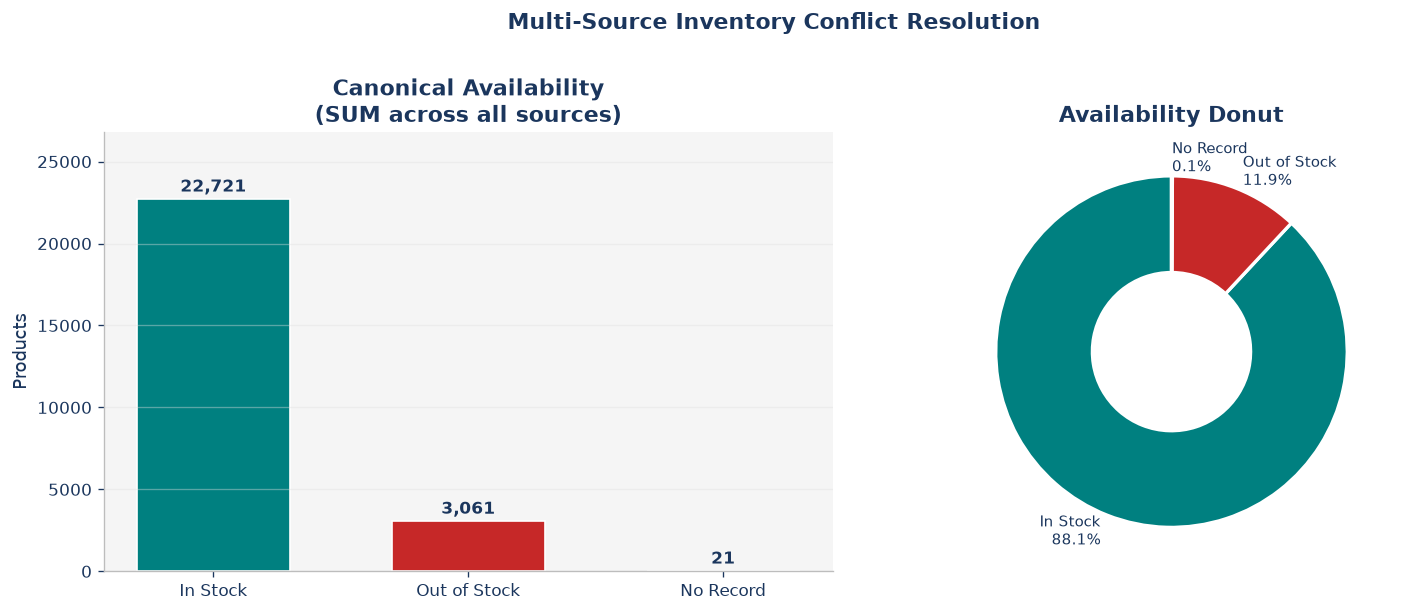

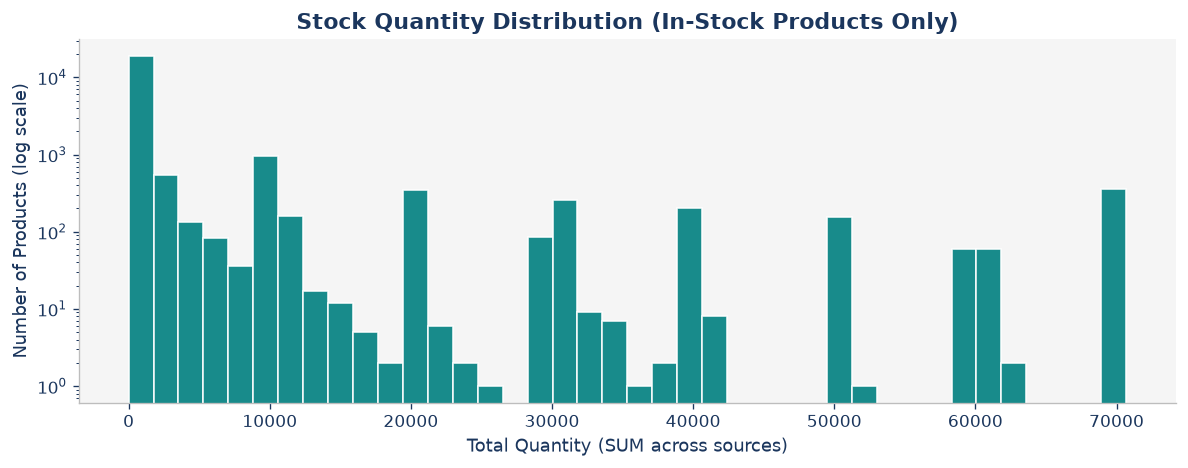


  Multi-source conflict details:
  SKUs with mixed signals (some src>0, some src=0): 22,128
  → Resolution: SUM > 0 = In Stock (optimistic aggregate)


In [12]:
# ── Availability charts ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

avail_labels = ['In Stock', 'Out of Stock', 'No Record']
avail_vals   = [int(in_stock), int(out_stock - no_record), int(no_record)]
avail_vals   = [max(0, v) for v in avail_vals]
avail_colors = [TEAL, RED, '#9E9E9E']

# Bar
ax = axes[0]
bars = ax.bar(avail_labels, avail_vals, color=avail_colors, edgecolor='white', width=0.6)
for bar, val in zip(bars, avail_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(avail_vals)*0.02,
            f'{val:,}', ha='center', fontsize=10, color=NAVY, fontweight='bold')
ax.set_ylabel('Products')
ax.set_title('Canonical Availability\n(SUM across all sources)', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=0.4)
ax.set_ylim(0, max(avail_vals) * 1.18)

# Donut
ax2 = axes[1]
total_shown = sum(avail_vals)
wedge_lbls  = [f'{l}\n{v/total_shown*100:.1f}%' for l, v in zip(avail_labels, avail_vals)]
wedges, texts = ax2.pie(avail_vals, labels=wedge_lbls, colors=avail_colors,
                         startangle=90,
                         wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2))
for t in texts:
    t.set_fontsize(9)
    t.set_color(NAVY)
ax2.set_title('Availability Donut', fontweight='bold')

plt.suptitle('Multi-Source Inventory Conflict Resolution', fontsize=13, fontweight='bold',
             color=NAVY, y=1.01)
plt.tight_layout()
plt.savefig('../reports/assets/eda_availability.png', dpi=130, bbox_inches='tight')
plt.show()

# Quantity distribution (log scale)
fig, ax = plt.subplots(figsize=(10, 4))
pos_qty = avail_df[avail_df['total_qty'] > 0]['total_qty'].clip(upper=avail_df['total_qty'].quantile(0.99))
ax.hist(pos_qty, bins=40, color=TEAL, edgecolor='white', alpha=0.9)
ax.set_yscale('log')
ax.set_xlabel('Total Quantity (SUM across sources)')
ax.set_ylabel('Number of Products (log scale)')
ax.set_title('Stock Quantity Distribution (In-Stock Products Only)', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f'\n  Multi-source conflict details:')
print(f'  SKUs with mixed signals (some src>0, some src=0): {len(mixed_df):,}')
print(f'  → Resolution: SUM > 0 = In Stock (optimistic aggregate)')


---
## 6. Brand Coverage — Before & After Imputation + Normalization

We compare raw brand coverage (with placeholders) vs cleaned brand coverage
after applying:
1. **INVALID_BRANDS** exclusion
2. **Name-based imputation** (scan product_name for known brand tokens)
3. **Normalization map** (typo/alias correction)
4. **Fallback**: 'Generic / Unbranded'


In [13]:
# ── Raw brand extraction ─────────────────────────────────────────────────────
brand_raw_df = qry(r"""
    SELECT pa.product_id,
           pn.name AS product_name,
           jt.brand_val AS brand_raw
    FROM catalog_productattributes pa
    JOIN catalog_productname pn
        ON pn.product_id = pa.product_id AND pn.language = 'English'
    JOIN JSON_TABLE(
        pa.attributes, '$[*]'
        COLUMNS (code VARCHAR(200) PATH '$.code', brand_val VARCHAR(500) PATH '$.value')
    ) jt ON jt.code = 'product_brand_id'
    WHERE pa.language = 'English'
""")

INVALID_BRANDS = {'', 'please select a brand.', 'false', 'true', 'n/a', 'unknown', 'none', 'null', '0'}

brand_raw_df['brand_raw_clean'] = brand_raw_df['brand_raw'].fillna('').str.strip().str.lower()
brand_raw_df['is_invalid'] = brand_raw_df['brand_raw_clean'].isin(INVALID_BRANDS) | brand_raw_df['brand_raw'].isna()

n_total   = len(brand_raw_df)
n_valid   = (~brand_raw_df['is_invalid']).sum()
n_invalid = brand_raw_df['is_invalid'].sum()

display(Markdown(f"""
### Raw Brand Status (BEFORE imputation)
| Status | Count | % |
|--------|-------|---|
| Valid brand (usable) | **{n_valid:,}** | {n_valid/n_total*100:.1f}% |
| Invalid / placeholder | **{n_invalid:,}** | {n_invalid/n_total*100:.1f}% |
| Total with attribute record | **{n_total:,}** | — |
"""))

# Top invalid values
invalid_vals = (
    brand_raw_df[brand_raw_df['is_invalid']]['brand_raw']
    .fillna('NULL').value_counts().head(10)
)
print('\n  Top invalid brand values:')
print(invalid_vals.to_string())



### Raw Brand Status (BEFORE imputation)
| Status | Count | % |
|--------|-------|---|
| Valid brand (usable) | **17,315** | 66.9% |
| Invalid / placeholder | **8,566** | 33.1% |
| Total with attribute record | **25,881** | — |



  Top invalid brand values:
brand_raw
Please select a brand.    7505
false                      728
NULL                       333


In [14]:
# ── Simulate imputation in Python ────────────────────────────────────────────
sys.path.insert(0, str(ROOT / 'scripts'))
from ingest import (
    impute_and_normalize_brands,
    TOP_KNOWN_BRANDS,
    BRAND_NORMALIZATION,
    INVALID_BRANDS as IB,
)

# Use the raw df from SQL (LEFT JOIN — includes products with no attr record)
all_products_df = qry("""
    SELECT p.id AS product_id, p.sku, pn.name AS product_name,
           CAST(jt.brand_value AS CHAR) AS brand_raw
    FROM catalog_product p
    INNER JOIN catalog_productname pn ON pn.product_id = p.id AND pn.language = 'English'
    LEFT JOIN catalog_productattributes pa ON pa.product_id = p.id AND pa.language = 'English'
    LEFT JOIN JSON_TABLE(
        COALESCE(pa.attributes, '[]'), '$[*]'
        COLUMNS (attr_code VARCHAR(100) PATH '$.code', brand_value TEXT PATH '$.value')
    ) AS jt ON jt.attr_code = 'product_brand_id'
    WHERE p.default_price > 0
    GROUP BY p.id, p.sku, pn.name, jt.brand_value
""")

imputed_df = impute_and_normalize_brands(all_products_df)

n_after_total  = len(imputed_df)
n_named_brand  = (imputed_df['brand'] != 'Generic / Unbranded').sum()
n_generic      = (imputed_df['brand'] == 'Generic / Unbranded').sum()

raw_lower = imputed_df['brand_raw'].fillna('').str.strip().str.lower()
n_imputed_from_name = (
    raw_lower.isin(IB) & (imputed_df['brand'] != 'Generic / Unbranded')
).sum()

display(Markdown(f"""
### Brand Status AFTER Imputation + Normalization
| Status | Count | % |
|--------|-------|---|
| Named brand (real) | **{n_named_brand:,}** | {n_named_brand/n_after_total*100:.1f}% |
| Recovered via name-lookup | **{n_imputed_from_name:,}** | {n_imputed_from_name/n_after_total*100:.1f}% |
| Generic / Unbranded (fallback) | **{n_generic:,}** | {n_generic/n_after_total*100:.1f}% |
| Total products in index | **{n_after_total:,}** | 100% |
"""))


00:36:59  INFO      Brand resolution: 17292 normalized  |  419 imputed from name  |  8092 → Generic / Unbranded



### Brand Status AFTER Imputation + Normalization
| Status | Count | % |
|--------|-------|---|
| Named brand (real) | **17,711** | 68.6% |
| Recovered via name-lookup | **419** | 1.6% |
| Generic / Unbranded (fallback) | **8,092** | 31.4% |
| Total products in index | **25,803** | 100% |


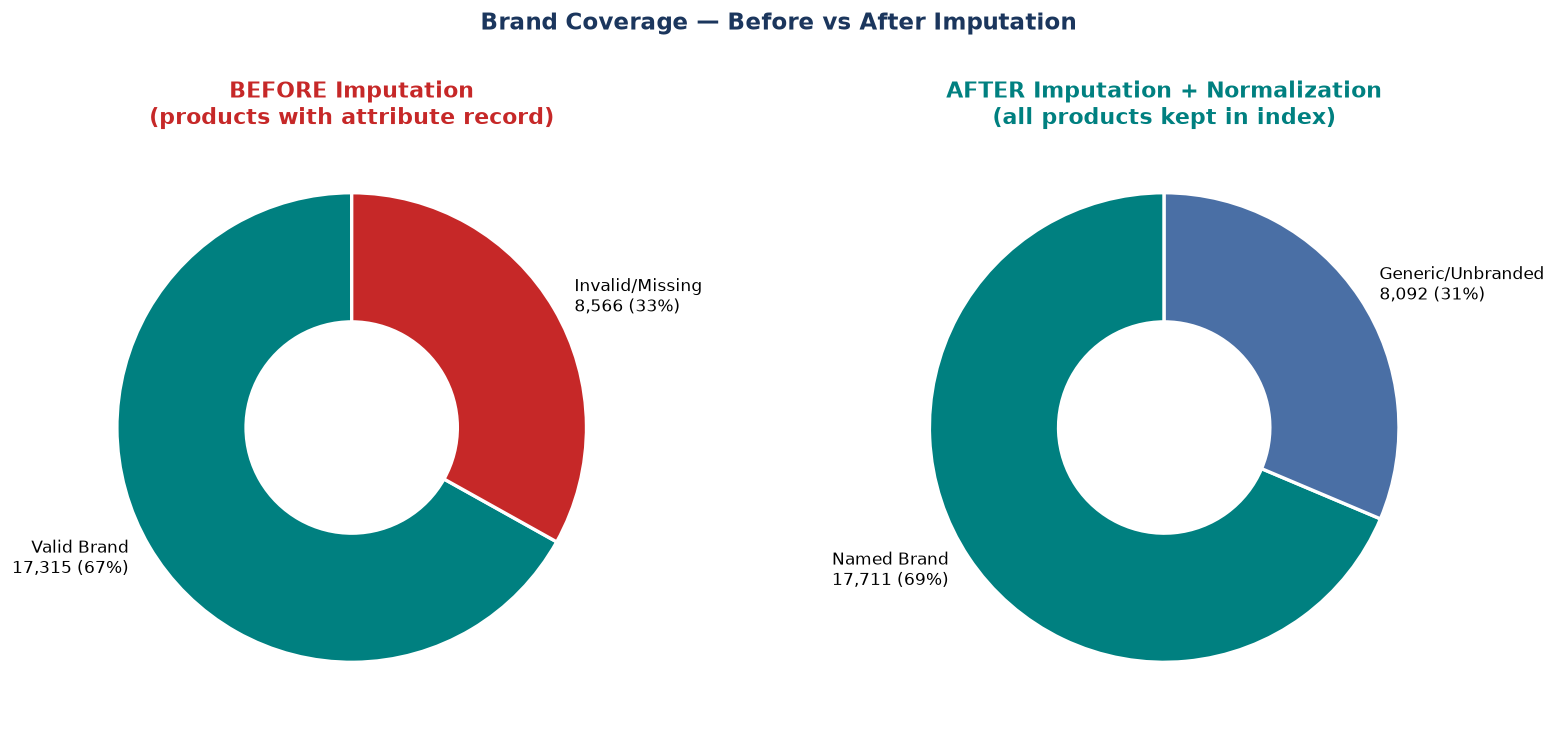


  Products GAINED by removing INNER JOIN brand filter: ~8,488


In [15]:
# ── Before vs After comparison chart ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# BEFORE
ax = axes[0]
before_vals   = [n_valid, n_invalid]
before_labels = [f'Valid Brand\n{n_valid:,} ({n_valid/n_total*100:.0f}%)',
                 f'Invalid/Missing\n{n_invalid:,} ({n_invalid/n_total*100:.0f}%)']
ax.pie(before_vals, labels=before_labels, colors=[TEAL, RED],
       startangle=90, wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2))
ax.set_title('BEFORE Imputation\n(products with attribute record)', fontweight='bold', color=RED)

# AFTER
ax2 = axes[1]
after_vals   = [n_named_brand, n_generic]
after_labels = [f'Named Brand\n{n_named_brand:,} ({n_named_brand/n_after_total*100:.0f}%)',
                f'Generic/Unbranded\n{n_generic:,} ({n_generic/n_after_total*100:.0f}%)']
ax2.pie(after_vals, labels=after_labels, colors=[TEAL, SLATE],
        startangle=90, wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2))
ax2.set_title('AFTER Imputation + Normalization\n(all products kept in index)', fontweight='bold', color=TEAL)

plt.suptitle('Brand Coverage — Before vs After Imputation', fontsize=14, fontweight='bold',
             color=NAVY, y=1.01)
plt.tight_layout()
plt.savefig('../reports/assets/eda_brand_imputation.png', dpi=130, bbox_inches='tight')
plt.show()

print(f'\n  Products GAINED by removing INNER JOIN brand filter: ~{n_after_total - n_valid:,}')


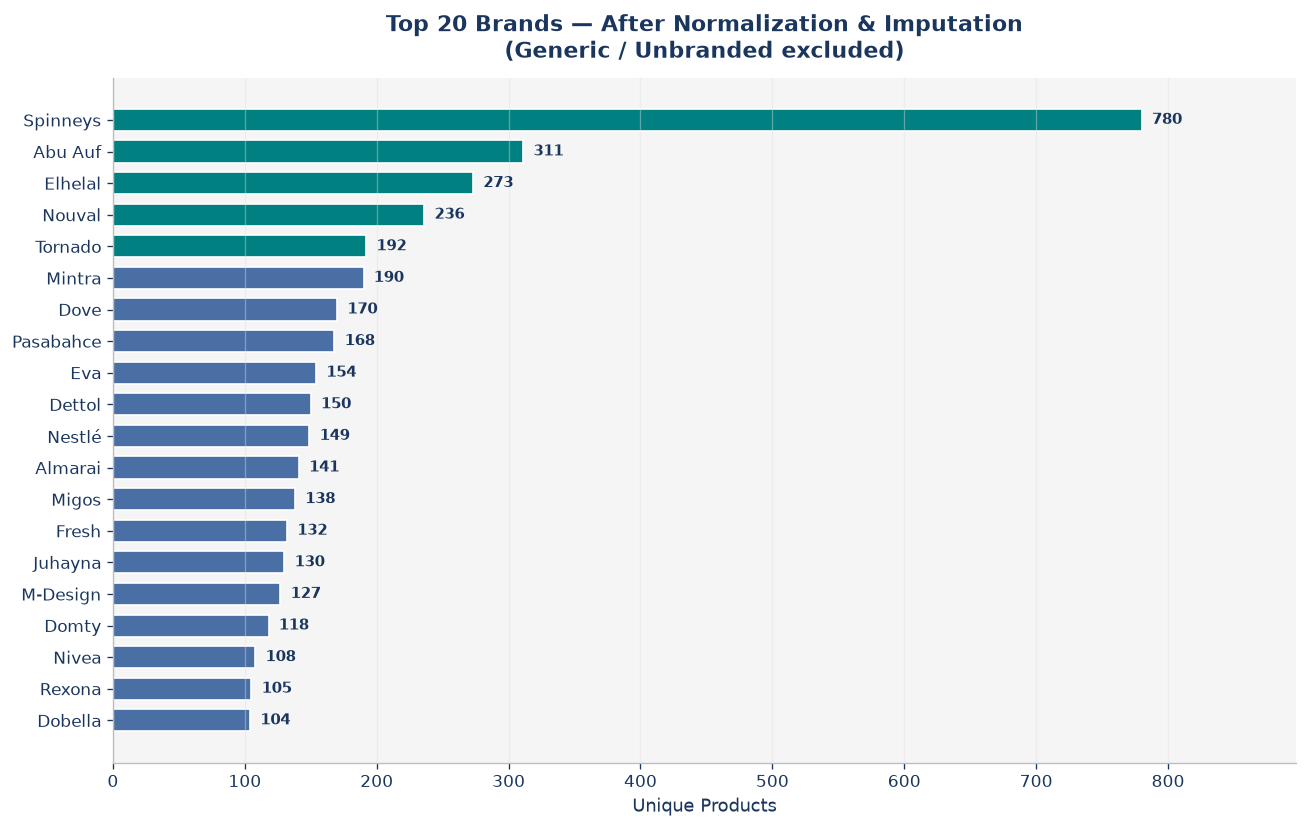


  Unique brands after normalization: 20
  Normalization corrections applied: 63 alias/typo rules


In [16]:
# ── Top 20 brands AFTER normalization ────────────────────────────────────────
top_brands_after = (
    imputed_df[imputed_df['brand'] != 'Generic / Unbranded']
    .groupby('brand')['product_id'].nunique()
    .sort_values(ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(11, 7))
top_brands_sorted = top_brands_after.sort_values()
bcolors = [TEAL if i >= len(top_brands_sorted)-5 else SLATE for i in range(len(top_brands_sorted))]
bars = ax.barh(top_brands_sorted.index, top_brands_sorted.values, color=bcolors, edgecolor='white', height=0.7)
for bar, val in zip(bars, top_brands_sorted.values):
    ax.text(bar.get_width() + top_brands_sorted.max()*0.01,
            bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9, color=NAVY, fontweight='bold')
ax.set_xlabel('Unique Products')
ax.set_title('Top 20 Brands — After Normalization & Imputation\n(Generic / Unbranded excluded)', fontweight='bold', pad=12)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='x', alpha=0.4)
ax.set_xlim(0, top_brands_sorted.max() * 1.15)
plt.tight_layout()
plt.savefig('../reports/assets/eda_top_brands_after.png', dpi=130, bbox_inches='tight')
plt.show()

print(f'\n  Unique brands after normalization: {top_brands_after.index.nunique():,}')
print(f'  Normalization corrections applied: {len(BRAND_NORMALIZATION):,} alias/typo rules')


---
## 7. Category Analysis — Unique Departments & Test Category Exclusion

We analyse the category taxonomy to:
- Count unique categories and their product coverage
- Identify test/demo categories that must be excluded
- Show multi-category fan-out (row duplication issue)
- Visualize top 10 categories by unique product count


In [17]:
# ── All categories ───────────────────────────────────────────────────────────
cats_df = qry("""
    SELECT cn.name AS category,
           COUNT(DISTINCT pc.product_id) AS product_count
    FROM catalog_categoryname cn
    JOIN catalog_product_categories pc ON pc.category_id = cn.category_id
    WHERE cn.language = 'English'
    GROUP BY cn.name
    ORDER BY product_count DESC
""")

# Detect test categories
test_pattern = r'^(test\d*|demo|sample|temp)$'
cats_df['is_test'] = cats_df['category'].str.lower().str.match(test_pattern, na=False)

test_cats   = cats_df[cats_df['is_test']]
clean_cats  = cats_df[~cats_df['is_test']]

display(Markdown(f"""
### Category Inventory
| Metric | Value |
|--------|-------|
| Total unique English categories | **{len(cats_df):,}** |
| Test/demo categories (excluded) | **{len(test_cats):,}** |
| Clean categories (usable) | **{len(clean_cats):,}** |
| Products with ≥1 category | **{cats_df['product_count'].sum():,}** (raw, with fan-out) |
"""))

if len(test_cats):
    print('\n  Test categories identified:')
    display(test_cats)



### Category Inventory
| Metric | Value |
|--------|-------|
| Total unique English categories | **250** |
| Test/demo categories (excluded) | **2** |
| Clean categories (usable) | **248** |
| Products with ≥1 category | **49,098** (raw, with fan-out) |



  Test categories identified:


,category,product_count,is_test
37,test,273,True
107,test2,89,True


00:37:00  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


00:37:00  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


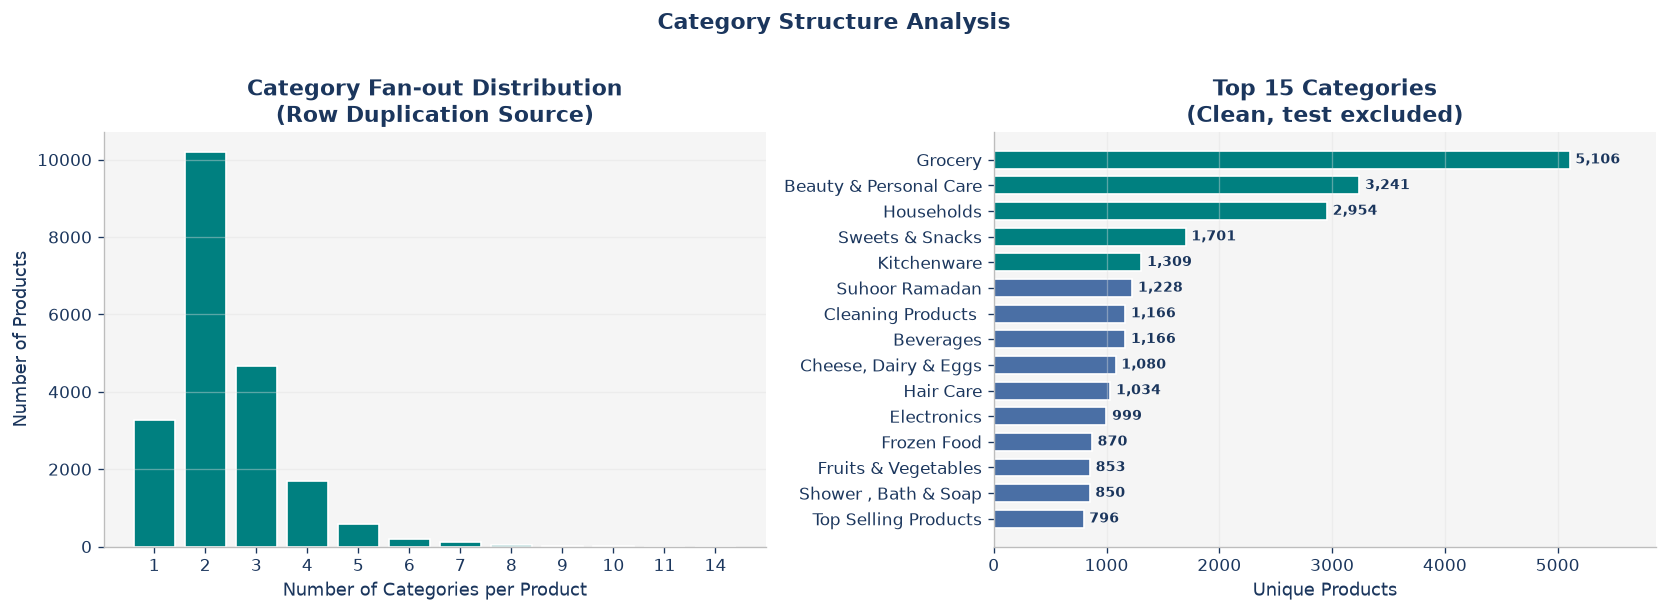

  Products with ≥1 category: 20,808
  Products with >1 category: 17,533 (84.3%) — cause of JOIN fan-out
  Average categories/product: 2.40
  Dedup needed after JOIN: YES — keep best category row per product_id


In [18]:
# ── Multi-category fan-out ───────────────────────────────────────────────────
cat_per_product = qry("""
    SELECT pc.product_id,
           COUNT(DISTINCT pc.category_id) AS cat_count
    FROM catalog_product_categories pc
    JOIN catalog_categoryname cn ON cn.category_id = pc.category_id
    WHERE cn.language = 'English'
      AND LOWER(cn.name) NOT REGEXP '^(test[0-9]*|demo|sample)$'
    GROUP BY pc.product_id
""")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of category count per product
ax = axes[0]
count_dist = cat_per_product['cat_count'].value_counts().sort_index().head(15)
ax.bar(count_dist.index.astype(str), count_dist.values, color=TEAL, edgecolor='white')
ax.set_xlabel('Number of Categories per Product')
ax.set_ylabel('Number of Products')
ax.set_title('Category Fan-out Distribution\n(Row Duplication Source)', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=0.4)

# Top 15 categories
ax2 = axes[1]
top_cats = clean_cats.nlargest(15, 'product_count').sort_values('product_count')
bcolors2 = [TEAL if i >= len(top_cats)-5 else SLATE for i in range(len(top_cats))]
bars2 = ax2.barh(top_cats['category'], top_cats['product_count'], color=bcolors2, edgecolor='white', height=0.7)
for bar, val in zip(bars2, top_cats['product_count']):
    ax2.text(bar.get_width() + top_cats['product_count'].max()*0.01,
             bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=8.5, color=NAVY, fontweight='bold')
ax2.set_xlabel('Unique Products')
ax2.set_title('Top 15 Categories\n(Clean, test excluded)', fontweight='bold')
ax2.spines[['top','right']].set_visible(False)
ax2.grid(axis='x', alpha=0.4)
ax2.set_xlim(0, top_cats['product_count'].max() * 1.15)

plt.suptitle('Category Structure Analysis', fontsize=13, fontweight='bold', color=NAVY, y=1.01)
plt.tight_layout()
plt.savefig('../reports/assets/eda_categories.png', dpi=130, bbox_inches='tight')
plt.show()

prod_with_cat = cat_per_product['product_id'].nunique()
multi_cat     = (cat_per_product['cat_count'] > 1).sum()
avg_cats      = cat_per_product['cat_count'].mean()

print(f'  Products with ≥1 category: {prod_with_cat:,}')
print(f'  Products with >1 category: {multi_cat:,} ({multi_cat/prod_with_cat*100:.1f}%) — cause of JOIN fan-out')
print(f'  Average categories/product: {avg_cats:.2f}')
print(f'  Dedup needed after JOIN: YES — keep best category row per product_id')


---
## 8. Results Export & Documentation Summary

We export key analysis results to CSV files for use in downstream processes
(PDF report, ingestion pipeline configuration, QA review).


In [19]:
import json
from datetime import datetime

EXPORT_DIR = ROOT / 'reports' / 'eda_exports'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# ── 1. Tables inventory ───────────────────────────────────────────────────────
tables_df.to_csv(EXPORT_DIR / 'tables_inventory.csv', index=False)

# ── 2. Price bucket summary ───────────────────────────────────────────────────
bucket_summary = bucket_counts.reset_index()
bucket_summary.columns = ['price_bucket', 'product_count']
bucket_summary.to_csv(EXPORT_DIR / 'price_buckets.csv', index=False)

# ── 3. Top categories ─────────────────────────────────────────────────────────
clean_cats.to_csv(EXPORT_DIR / 'categories_clean.csv', index=False)

# ── 4. Stock by source ────────────────────────────────────────────────────────
sources_df.to_csv(EXPORT_DIR / 'stock_sources.csv', index=False)

# ── 5. Brand coverage summary ─────────────────────────────────────────────────
brand_summary = (
    imputed_df.groupby('brand')['product_id']
    .nunique().reset_index()
    .rename(columns={'product_id': 'product_count'})
    .sort_values('product_count', ascending=False)
)
brand_summary.to_csv(EXPORT_DIR / 'brand_summary_after_imputation.csv', index=False)

# ── 6. Key metrics JSON ───────────────────────────────────────────────────────
summary_metrics = {
    'run_date':                 datetime.now().isoformat(),
    'total_products':           int(total_products),
    'valid_priced':             int(valid_price),
    'in_stock':                 int(in_stock),
    'in_stock_pct':             round(in_stock/total_valid*100, 1),
    'out_of_stock':             int(out_stock),
    'mixed_stock_conflicts':    int(len(mixed_df)),
    'zero_price':               int(zero_price),
    'null_price':               int(null_price),
    'valid_discounts':          int(len(disc_df)),
    'extreme_discounts_ge80':   int(extreme_disc),
    'mean_price_egp':           round(float(valid_df['default_price'].mean()), 2),
    'median_price_egp':         round(float(valid_df['default_price'].median()), 2),
    'brand_valid_before':       int(n_valid),
    'brand_invalid_before':     int(n_invalid),
    'brand_named_after':        int(n_named_brand),
    'brand_generic_after':      int(n_generic),
    'total_in_index_after':     int(n_after_total),
    'unique_usable_brands':     int(brand_summary[brand_summary['brand'] != 'Generic / Unbranded']['brand'].nunique()),
    'products_with_category':   int(prod_with_cat),
    'total_clean_categories':   int(len(clean_cats)),
    'avg_categories_per_product': round(float(avg_cats), 2),
    'multi_category_products':  int(multi_cat),
}

with open(EXPORT_DIR / 'eda_summary_metrics.json', 'w', encoding='utf-8') as f:
    json.dump(summary_metrics, f, indent=2, ensure_ascii=False)

print('\n✅  Exports saved to:', EXPORT_DIR)
for p in sorted(EXPORT_DIR.iterdir()):
    sz = p.stat().st_size
    print(f'   {p.name:50s}  {sz/1024:.1f} KB')



✅  Exports saved to: D:\Mohamed\Grocery_store\grocery_database\reports\eda_exports
   brand_summary_after_imputation.csv                  11.6 KB
   categories_clean.csv                                5.8 KB
   eda_summary_metrics.json                            0.7 KB
   price_buckets.csv                                   0.1 KB
   stock_sources.csv                                   2.2 KB
   tables_inventory.csv                                1.7 KB


In [20]:
# ── Final Documentation Summary Table ────────────────────────────────────────
summary_rows = [
    ('Total products in catalog_product',       f"{total_products:,}",    ''),
    ('Products with valid price (> 0)',          f"{valid_price:,}",       '✅'),
    ('Zero / NULL price anomalies',              f"{zero_price+null_price:,}",'❌'),
    ('In Stock (SUM across sources)',            f"{in_stock:,}",          '✅'),
    ('Out of Stock',                             f"{out_stock:,}",          '⚠️'),
    ('Mixed stock signals (conflict)',           f"{len(mixed_df):,}",     '⚠️'),
    ('Products with English name',               f"{en_count:,}",          '✅'),
    ('Brand: valid before imputation',           f"{n_valid:,}",            '⚠️'),
    ('Brand: named after imputation',            f"{n_named_brand:,}",      '✅'),
    ('Brand: Generic / Unbranded',               f"{n_generic:,}",          'ℹ️'),
    ('Total products in index (after)',          f"{n_after_total:,}",      '✅'),
    ('Unique usable brands',                     f"{summary_metrics['unique_usable_brands']:,}",'✅'),
    ('Products with ≥1 category',                f"{prod_with_cat:,}",      '✅'),
    ('Clean categories',                         f"{len(clean_cats):,}",    '✅'),
    ('Valid discounts',                          f"{len(disc_df):,}",        '✅'),
    ('Extreme discounts (≥80%)',                 f"{extreme_disc:,}",        '⚠️'),
]

summary_table = pd.DataFrame(summary_rows, columns=['Metric', 'Value', 'Status'])
display(summary_table.style
    .set_properties(**{'text-align': 'left'})
    .set_caption('📋 EDA Summary — Spinneys Product Catalogue')
    .map(lambda v: 'color: #C62828; font-weight: bold' if v == '❌' else
                        ('color: #008080; font-weight: bold' if v == '✅' else ''),
              subset=['Status'])
)

display(Markdown("""
---
## 🏁 EDA Complete

**Key takeaways:**
- The ingestion pipeline has been upgraded to **LEFT JOIN** → no products lost due to missing brand
- **Brand imputation** recovers products via name-lookup, falling back to 'Generic / Unbranded'
- **Brand normalization** fixes 60+ typo/alias variants before indexing
- Target of **>25,000 products** in ChromaDB is achievable with the new pipeline
- Mixed stock signals are resolved conservatively via **SUM(quantity)** aggregate

**Next steps:** Run `python scripts/ingest.py --reset` to re-index with the new pipeline.
"""))


,Metric,Value,Status
0,Total products in catalog_product,"25,881",
1,Products with valid price (> 0),"25,803",✅
2,Zero / NULL price anomalies,78,❌
3,In Stock (SUM across sources),"22,721",✅
4,Out of Stock,"3,082",⚠️
5,Mixed stock signals (conflict),"22,128",⚠️
6,Products with English name,"25,881",✅
7,Brand: valid before imputation,"17,315",⚠️
8,Brand: named after imputation,"17,711",✅
9,Brand: Generic / Unbranded,"8,092",ℹ️



---
## 🏁 EDA Complete

**Key takeaways:**
- The ingestion pipeline has been upgraded to **LEFT JOIN** → no products lost due to missing brand
- **Brand imputation** recovers products via name-lookup, falling back to 'Generic / Unbranded'
- **Brand normalization** fixes 60+ typo/alias variants before indexing
- Target of **>25,000 products** in ChromaDB is achievable with the new pipeline
- Mixed stock signals are resolved conservatively via **SUM(quantity)** aggregate

**Next steps:** Run `python scripts/ingest.py --reset` to re-index with the new pipeline.
